# Gates, MUX, K-maps, Greek letters, and power three ways

1. The Greek alphabet, Alpha to Omega, as SymPy symbols
2. The 7 basic gates and why NAND alone is enough
3. Multiplexers
4. Karnaugh maps, checked against SymPy's minimizer
5. Power three ways, and energy from geometry, mass, and charge: E = P t

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()))
import sympy as sp
sp.init_printing(use_unicode=True)
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from dgs import digital_logic_power as D

## 1. Greek alphabet

In [2]:
display(pd.DataFrame([(n, sp.pretty(lo), sp.pretty(up), use) for n, lo, up, use in D.greek_alphabet()],
                     columns=["name", "lower", "upper", "usually means"]))
lam, omega, tau = sp.symbols("lambda omega tau")
display(sp.Eq(sp.Symbol("f"), 1 / (2 * sp.pi * tau)), sp.Eq(omega, 2 * sp.pi * sp.Symbol("c") / lam))

,name,lower,upper,usually means
0,alpha,α,Α,angle; alpha particle; fine-structure constant
1,beta,β,Β,v/c in relativity; beta decay; transistor curr...
2,gamma,γ,Γ,Lorentz factor; gamma ray; photon
3,delta,δ,Δ,small change; Dirac delta; skin depth
4,epsilon,ε,Ε,permittivity epsilon_0; small quantity; emissi...
5,zeta,ζ,Ζ,damping ratio in 2nd-order circuits
6,eta,η,Η,efficiency
7,theta,θ,Θ,angle; phase
8,iota,ι,Ι,rarely used (index)
9,kappa,κ,Κ,dielectric constant; thermal conductivity


## 2. The 7 basic gates

NOT, AND, OR, NAND, NOR, XOR, XNOR. NAND is **universal**: each gate below is rebuilt from
NAND gates only, then checked against the real gate on every input.

In [3]:
rows = {}
for g in D.GATES:
    tt = D.truth_table(g)
    rows[g] = {("A=%d" % r[0] if g == "NOT" else "AB=%d%d" % r[:2]): r[-1] for r in tt}
display(pd.DataFrame(rows).T.fillna("").astype(str))
display(pd.DataFrame([(g, D.GATE_EXPR[g], D.NAND_COUNT[g]) for g in D.GATES],
                     columns=["gate", "Boolean expression", "NAND gates needed"]))
print("NAND-only builds match every gate:", D.check_nand_universality())

,A=0,A=1,AB=00,AB=01,AB=10,AB=11
NOT,1.0,0.0,,,,
AND,,,0.0,0.0,0.0,1.0
OR,,,0.0,1.0,1.0,1.0
NAND,,,1.0,1.0,1.0,0.0
NOR,,,1.0,0.0,0.0,0.0
XOR,,,0.0,1.0,1.0,0.0
XNOR,,,1.0,0.0,0.0,1.0


,gate,Boolean expression,NAND gates needed
0,NOT,~A,1
1,AND,A & B,2
2,OR,A | B,3
3,NAND,~(A & B),1
4,NOR,~(A | B),4
5,XOR,A ^ B,4
6,XNOR,~(A ^ B),5


NAND-only builds match every gate: True


## 3. Multiplexer

A 2^k:1 MUX passes data input number `select` to the output. Put the variables on the select
lines and the truth-table column on the data lines, and the MUX *is* that function.

In [4]:
expr, S, Dsym = D.mux_expression(2)
display(expr)
data = D.function_via_mux([1, 2, 4, 7], 3)        # 3-input odd parity (XOR of A, B, C)
print("data inputs D0..D7 for parity:", data)
for sel in [(0, 0, 0), (0, 1, 1), (1, 1, 1)]:
    print(f"ABC={''.join(map(str, sel))}  ->  {D.mux(sel, data)}")

data inputs D0..D7 for parity: [0, 1, 1, 0, 1, 0, 0, 1]
ABC=000  ->  0
ABC=011  ->  0
ABC=111  ->  1


## 4. Karnaugh maps

Rows and columns are in **Gray code**, so neighbouring cells differ in one variable and
adjacent 1s can be grouped. The minimal sum of products comes from SymPy's `SOPform`
(Quine-McCluskey), then `verify_sop` checks it on every input.

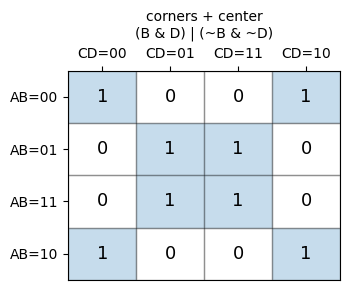

verified: True | literals: 4


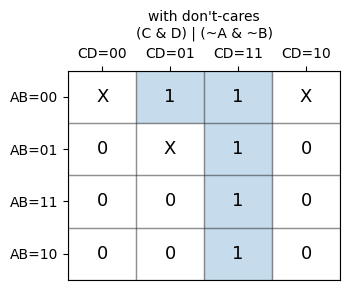

verified: True | literals: 4


In [5]:
def draw_kmap(minterms, variables, dontcares=(), title=""):
    grid, rows, cols, sop = D.kmap(minterms, variables, dontcares)
    fig, ax = plt.subplots(figsize=(3.6, 3.0))
    for i, line in enumerate(grid):
        for j, cell in enumerate(line):
            ax.add_patch(plt.Rectangle((j, -i), 1, 1, fill=cell == 1, alpha=0.25, ec="k"))
            ax.text(j + 0.5, -i + 0.5, cell, ha="center", va="center", fontsize=13)
    ax.set_xlim(0, len(cols)); ax.set_ylim(-len(rows) + 1, 1)
    ax.set_xticks([j + 0.5 for j in range(len(cols))]); ax.set_xticklabels(cols)
    ax.set_yticks([-i + 0.5 for i in range(len(rows))]); ax.set_yticklabels(rows)
    ax.xaxis.tick_top(); ax.set_title(f"{title}\n{sp.sstr(sop)}", fontsize=10, pad=24)
    plt.tight_layout(); plt.show()
    print("verified:", D.verify_sop(sop, minterms, variables, dontcares), "| literals:", D.literal_count(sop))
    return sop

draw_kmap([0, 2, 5, 7, 8, 10, 13, 15], list("ABCD"), title="corners + center")
draw_kmap([1, 3, 7, 11, 15], list("ABCD"), dontcares=[0, 2, 5], title="with don't-cares")

## 5. Power three ways, and E = P t

| Definition | Formula | Where |
|---|---|---|
| rate of doing work | P = dW/dt | anything |
| force times velocity | P = F · v | mechanics |
| current times voltage | P = IV = I²R = V²/R | circuits |

All three are the same quantity: SymPy converts each to watts.

In [6]:
display(pd.DataFrame(D.POWER_DEFINITIONS, columns=["definition", "formula", "use"]))
print("each form is exactly 1 W per unit:", D.check_power_units())
print("12 V across 6 ohm:", D.power_electrical(V=12, R=6), "W")
print("lift 10 kg at 1.2 m/s:", round(D.power_force_velocity(10 * D.G_EARTH, 1.2), 1), "W")

,definition,formula,use
0,rate of doing work,P = dW/dt,"any energy transfer: lifting, heating, a batte..."
1,force times velocity,P = F . v,"mechanics: a motor pulling a load, drag on a car"
2,current times voltage,P = I V (= I^2 R = V^2 / R for a resistor),circuits: EEE 117


each form is exactly 1 W per unit: {'W/t': True, 'F v': True, 'I V': True, 'I^2 R': True, 'V^2/R': True}
12 V across 6 ohm: 24.0 W
lift 10 kg at 1.2 m/s: 117.7 W


In [7]:
sources = [
    ("geometry: 1 cm^2 plates, 1 mm gap, 10 V", D.energy_capacitor_geometry(1e-4, 1e-3, 10)),
    ("mass: 70 kg climbing 3 m of stairs", D.energy_from_mass(70, h=3)),
    ("mass: 1 g fully converted, E = mc^2", D.energy_from_mass(1e-3, rest=True)),
    ("charge: electron through 1 V (1 eV)", D.energy_from_charge(1.602176634e-19, V=1)),
    ("charge: two 1 uC charges 10 cm apart", D.energy_from_charge(1e-6, q2_C=1e-6, r_m=0.1)),
]
display(pd.DataFrame([(k, f"{E:.3e}") for k, E in sources], columns=["source", "energy (J)"]))
r = D.energy_power_time(E=D.energy_from_mass(70, h=3), t=4.0)
print(f"stairs in 4 s: P = {r['P_W']:.0f} W;  a 60 W bulb for 1 h uses",
      D.energy_power_time(P=60, t=3600)["E_J"], "J")

,source,energy (J)
0,"geometry: 1 cm^2 plates, 1 mm gap, 10 V",4.427e-11
1,mass: 70 kg climbing 3 m of stairs,2.059e+03
2,"mass: 1 g fully converted, E = mc^2",8.988e+13
3,charge: electron through 1 V (1 eV),1.602e-19
4,charge: two 1 uC charges 10 cm apart,8.988e-02


stairs in 4 s: P = 515 W;  a 60 W bulb for 1 h uses 216000 J
